# West African Taro Leaf Blight Classification MLOps Pipeline

This project develops an image-classification pipeline that identifies four taro-leaf conditions: Healthy, Early Blight, Mid Blight and Late Blight. The dataset contains 18,248 smartphone images collected under natural field conditions in Nigeria and Ghana and reviewed by plant-pathology experts. It is available under the CC BY 4.0 licence from [Mendeley Data](https://doi.org/10.17632/3knm93dkc5.2), while the classification-ready version is hosted on [Hugging Face](https://huggingface.co/datasets/Project-AgML/taro_blight_stage_classification). This notebook covers data acquisition, validation, exploratory analysis, image-feature visualization, preprocessing, stratified splitting, MobileNetV2 transfer learning, fine-tuning, evaluation, error analysis and model export. The exported model will later support FastAPI prediction, bulk labelled-image upload and user-triggered retraining. This is an educational prototype and should not replace advice from a qualified plant pathologist.

In [9]:
%pip install -q datasets

## 1. Drive mounting

In [10]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/MLOps_Taro_Leaf_Blight"
)
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
FIGURE_DIR = PROJECT_DIR / "figures"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project directory: {PROJECT_DIR}")
print(f"Artifact directory: {ARTIFACT_DIR}")
print(f"Figure directory: {FIGURE_DIR}")

Mounted at /content/drive
Project directory: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight
Artifact directory: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts
Figure directory: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/figures


### Required libraries

TensorFlow is used for image processing and model training. Pandas and NumPy
are used for dataset metadata and numerical operations. Scikit-learn provides
stratified splitting and evaluation metrics. Pillow loads images for feature
analysis, while Matplotlib and Seaborn produce visualizations.

In [11]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from datasets import load_dataset
from PIL import Image, ImageFilter, ImageStat, UnidentifiedImageError
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Data acquisition

The dataset is downloaded programmatically from its classification-ready
repository. Programmatic acquisition makes the experiment reproducible and
avoids requiring each user to organize thousands of images manually.

The repository currently provides one complete dataset split. This notebook
will create separate stratified training, validation and test splits after
validating the labels and images.

In [12]:
DATASET_ID = (
    "Project-AgML/"
    "taro_blight_stage_classification"
)

dataset = load_dataset(DATASET_ID, split="train")

print(dataset)
print("\nFeatures:")
print(dataset.features)

README.md:   0%|          | 0.00/1.55k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  441MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  422MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  412MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18248 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 18248
})

Features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Early_Blight', 'Healthy', 'Late_Blight', 'Mid_Blight'])}


In [13]:
class_names = dataset.features["label"].names
labels = np.asarray(dataset["label"], dtype=np.int32)

expected_classes = {
    "Early_Blight",
    "Healthy",
    "Late_Blight",
    "Mid_Blight",
}

assert len(dataset) == 18_248
assert set(class_names) == expected_classes
assert "Not_Early" not in class_names

class_counts = (
    pd.Series(labels)
    .map(dict(enumerate(class_names)))
    .value_counts()
    .reindex(class_names)
    .rename_axis("class_name")
    .reset_index(name="image_count")
)

class_counts["percentage"] = (
    class_counts["image_count"] / len(dataset) * 100
).round(2)

display(class_counts)

print(f"Total images: {len(dataset):,}")
print(f"Classes: {class_names}")
print("Dataset verification passed.")

,class_name,image_count,percentage
0,Early_Blight,4864,26.65
1,Healthy,8744,47.92
2,Late_Blight,1270,6.96
3,Mid_Blight,3370,18.47


Total images: 18,248
Classes: ['Early_Blight', 'Healthy', 'Late_Blight', 'Mid_Blight']
Dataset verification passed.


## Data validation and visual inspection

Random samples from every class are displayed to confirm that images decode correctly and that their visible conditions correspond to the supplied disease-stage labels.

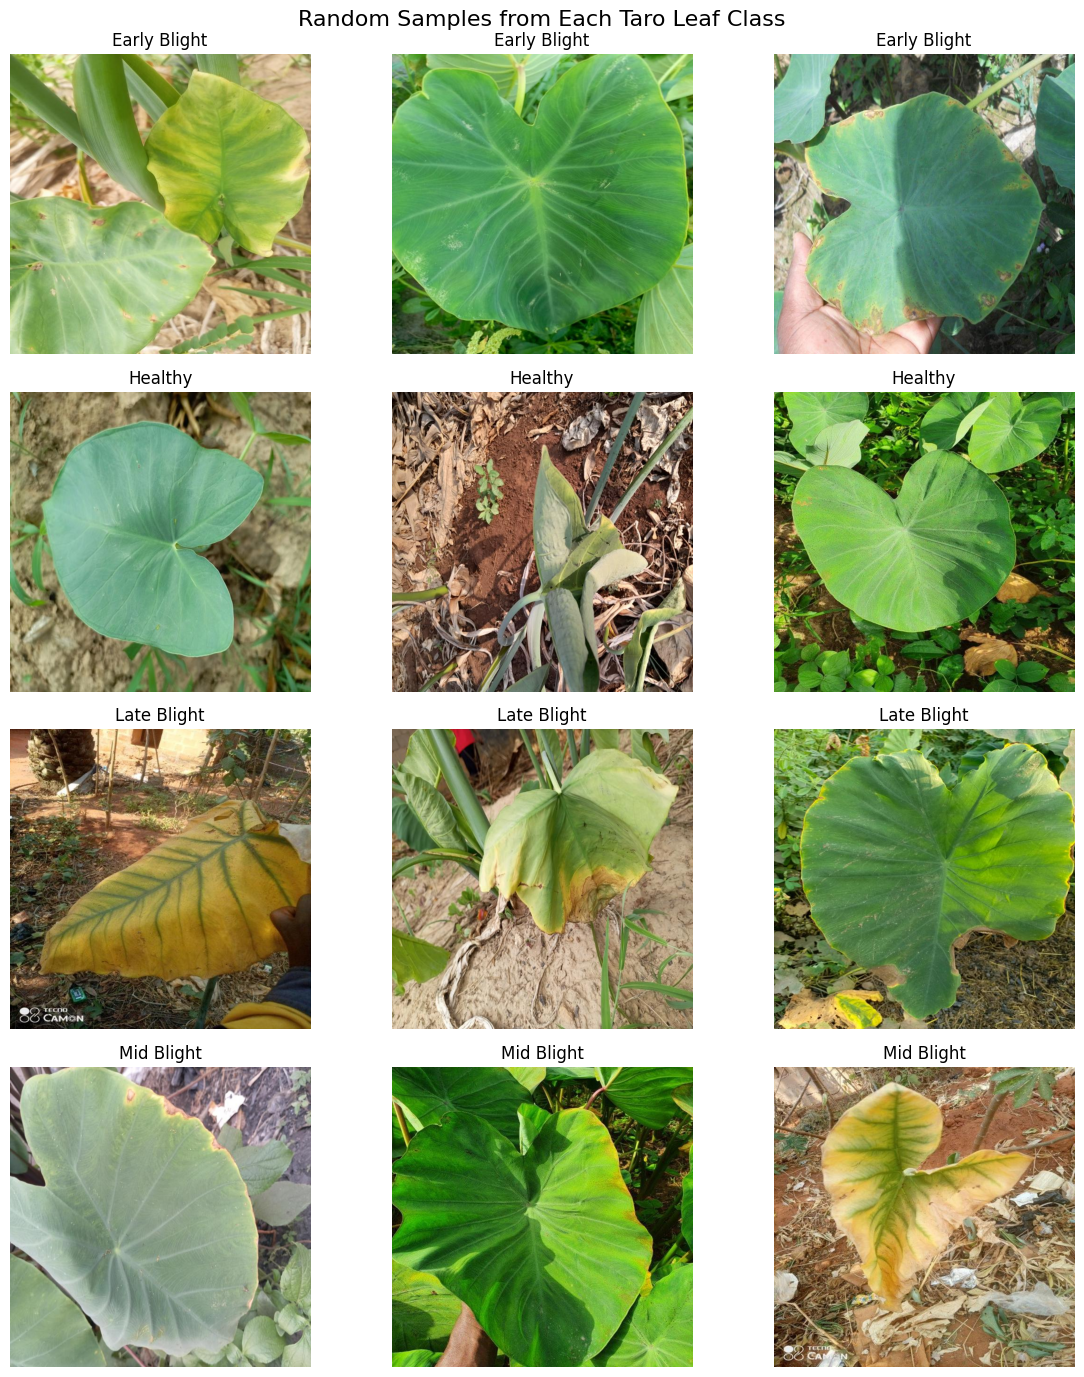

In [14]:
samples_per_class = 3

fig, axes = plt.subplots(
    len(class_names),
    samples_per_class,
    figsize=(12, 14),
)

rng = np.random.default_rng(SEED)

for row_index, class_name in enumerate(class_names):
    class_index = class_names.index(class_name)
    matching_indices = np.where(labels == class_index)[0]
    selected_indices = rng.choice(
        matching_indices,
        size=samples_per_class,
        replace=False,
    )

    for column_index, dataset_index in enumerate(selected_indices):
        example = dataset[int(dataset_index)]
        image = example["image"].convert("RGB")

        axes[row_index, column_index].imshow(image)
        axes[row_index, column_index].set_title(
            class_name.replace("_", " ")
        )
        axes[row_index, column_index].axis("off")

plt.suptitle(
    "Random Samples from Each Taro Leaf Class",
    fontsize=16,
)
plt.tight_layout()
plt.show()

## Exploratory data analysis

The class distribution is examined for imbalance. Four interpretable visual features are then measured from a balanced sample: brightness, colour saturation, green-pixel proportion and edge density. These features help explain visual differences between disease stages but are used only for interpretation; MobileNetV2 will learn directly from image pixels.

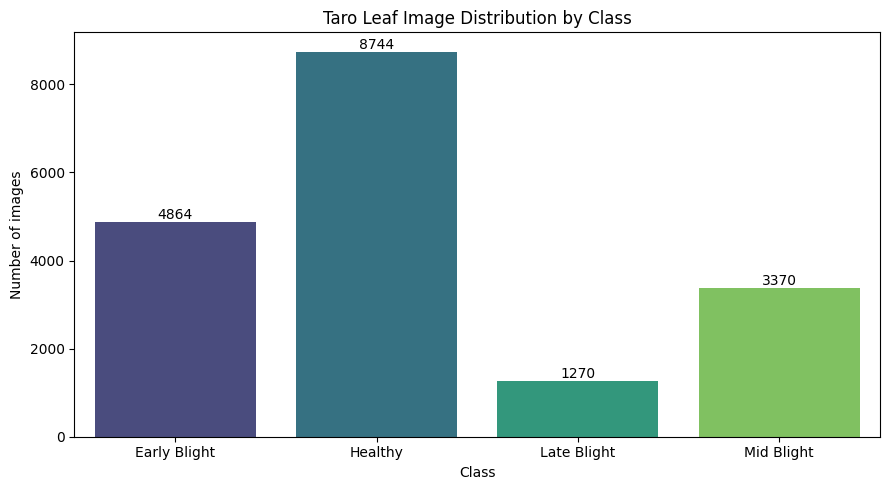

In [15]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=class_counts,
    x="class_name",
    y="image_count",
    hue="class_name",
    legend=False,
    palette="viridis",
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.title("Taro Leaf Image Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(
    ticks=range(len(class_names)),
    labels=[name.replace("_", " ") for name in class_names],
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "class_distribution.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [16]:
#Feature extraction

from matplotlib.colors import rgb_to_hsv

FEATURES_PER_CLASS = 600
FEATURE_IMAGE_SIZE = (128, 128)

rng = np.random.default_rng(SEED)
feature_indices = []

for class_index in range(len(class_names)):
    matching_indices = np.where(labels == class_index)[0]

    selected_indices = rng.choice(
        matching_indices,
        size=min(FEATURES_PER_CLASS, len(matching_indices)),
        replace=False,
    )

    feature_indices.extend(selected_indices.tolist())


def extract_visual_features(image):
    image = image.convert("RGB")
    image = image.resize(
        FEATURE_IMAGE_SIZE,
        Image.Resampling.BILINEAR,
    )

    rgb = np.asarray(image, dtype=np.float32) / 255.0
    hsv = rgb_to_hsv(rgb)

    grayscale = (
        0.299 * rgb[:, :, 0]
        + 0.587 * rgb[:, :, 1]
        + 0.114 * rgb[:, :, 2]
    )

    brightness = float(grayscale.mean())
    saturation = float(hsv[:, :, 1].mean())

    hue = hsv[:, :, 0]
    value = hsv[:, :, 2]

    green_mask = (
        (hue >= 0.17)
        & (hue <= 0.47)
        & (hsv[:, :, 1] >= 0.20)
        & (value >= 0.15)
    )
    green_ratio = float(green_mask.mean())

    horizontal_edges = np.abs(np.diff(grayscale, axis=1))
    vertical_edges = np.abs(np.diff(grayscale, axis=0))

    edge_density = float(
        (
            (horizontal_edges > 0.12).mean()
            + (vertical_edges > 0.12).mean()
        )
        / 2
    )

    return {
        "brightness": brightness,
        "saturation": saturation,
        "green_ratio": green_ratio,
        "edge_density": edge_density,
    }


feature_records = []

for position, dataset_index in enumerate(feature_indices, start=1):
    example = dataset[int(dataset_index)]
    class_name = class_names[example["label"]]

    record = {
        "dataset_index": int(dataset_index),
        "class_name": class_name,
    }
    record.update(extract_visual_features(example["image"]))
    feature_records.append(record)

    if position % 500 == 0:
        print(
            f"Processed {position:,} of "
            f"{len(feature_indices):,} images"
        )

features_df = pd.DataFrame(feature_records)

print(f"Feature records created: {len(features_df):,}")
display(features_df.head())

Processed 500 of 2,400 images
Processed 1,000 of 2,400 images
Processed 1,500 of 2,400 images
Processed 2,000 of 2,400 images
Feature records created: 2,400


,dataset_index,class_name,brightness,saturation,green_ratio,edge_density
0,16907,Early_Blight,0.663531,0.256329,0.880005,0.000830
1,15117,Early_Blight,0.640396,0.171983,0.246399,0.012857
2,16660,Early_Blight,0.412176,0.418857,0.532227,0.114450
3,17854,Early_Blight,0.573595,0.290333,0.773865,0.006336
4,18101,Early_Blight,0.506808,0.613862,0.987854,0.049028


In [17]:
feature_columns = [
    "brightness",
    "saturation",
    "green_ratio",
    "edge_density",
]

feature_summary = (
    features_df
    .groupby("class_name")[feature_columns]
    .agg(["mean", "std"])
    .round(4)
)

display(feature_summary)

brightness         saturation         green_ratio          \
                   mean     std       mean     std        mean     std   
class_name                                                               
Early_Blight     0.5028  0.0648     0.4269  0.1451      0.6230  0.2648   
Healthy          0.4882  0.0604     0.4210  0.1467      0.6111  0.2780   
Late_Blight      0.4869  0.0643     0.4301  0.1388      0.4081  0.2565   
Mid_Blight       0.4798  0.0680     0.4448  0.1636      0.6026  0.2615   

             edge_density          
                     mean     std  
class_name                         
Early_Blight       0.0626  0.0461  
Healthy            0.0696  0.0469  
Late_Blight        0.0994  0.0553  
Mid_Blight         0.0649  0.0420

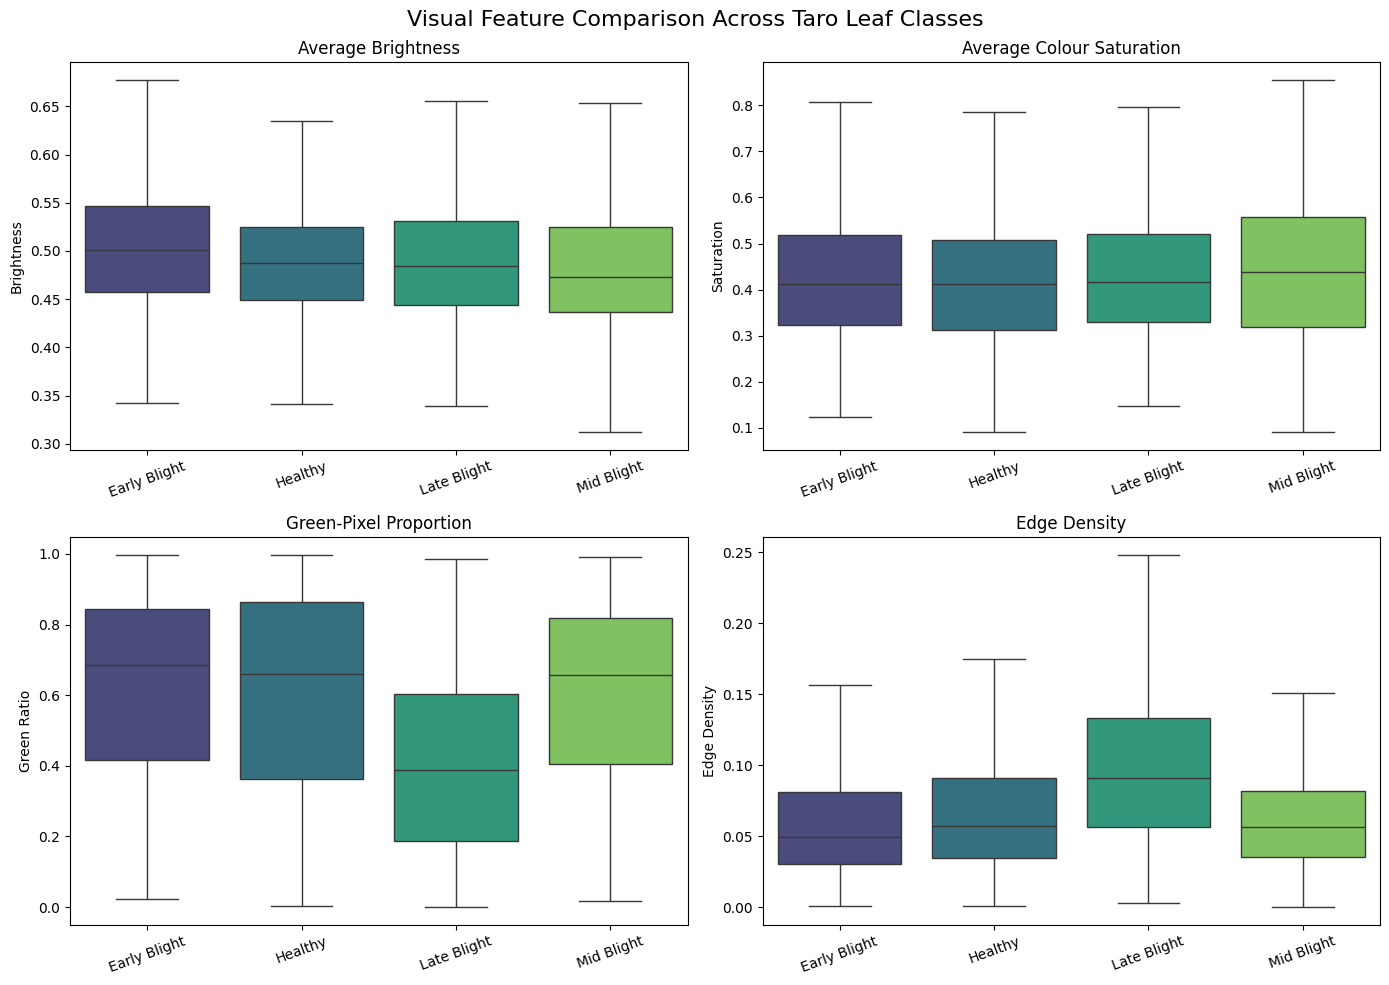

In [18]:
feature_titles = {
    "brightness": "Average Brightness",
    "saturation": "Average Colour Saturation",
    "green_ratio": "Green-Pixel Proportion",
    "edge_density": "Edge Density",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for axis, feature_name in zip(axes, feature_columns):
    sns.boxplot(
        data=features_df,
        x="class_name",
        y=feature_name,
        order=class_names,
        hue="class_name",
        palette="viridis",
        legend=False,
        showfliers=False,
        ax=axis,
    )

    axis.set_title(feature_titles[feature_name])
    axis.set_xlabel("")
    axis.set_ylabel(feature_name.replace("_", " ").title())
    axis.tick_params(axis="x", rotation=20)

    axis.set_xticks(range(len(class_names)))
    axis.set_xticklabels(
        [name.replace("_", " ") for name in class_names],
        rotation=20,
    )

plt.suptitle(
    "Visual Feature Comparison Across Taro Leaf Classes",
    fontsize=16,
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "feature_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Feature interpretation

Based on my observation, the dataset is imbalanced: Healthy contains 8,744 images, while Late Blight contains only 1,270. Without correction, the model could favour the Healthy class, so training will use class weights and evaluation will include macro-averaged metrics.

Late Blight has the lowest mean green-pixel proportion (0.4081) and the highest mean edge density (0.0994). This suggests that advanced disease is associated with reduced green leaf coverage and more irregular visual texture. Early Blight has the highest mean brightness (0.5028), while Mid Blight has the highest mean saturation (0.4448), although these differences are relatively small.

The substantial overlap between the class distributions shows that brightness, saturation, greenness or edge density alone cannot reliably determine disease stage. A convolutional neural network is therefore needed to learn more complex combinations of lesions, colour changes, leaf texture and shape. Background vegetation and soil may also influence these measurements, which is a limitation of whole-image feature extraction.

## Data splitting

The dataset is divided into 70% training, 15% validation and 15% test sets using stratified sampling. Stratification preserves the original class proportions in every split. The test set will remain unused until final model evaluation.

In [19]:
all_indices = np.arange(len(dataset))

train_indices, temporary_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels,
)

validation_indices, test_indices = train_test_split(
    temporary_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temporary_indices],
)

train_labels = labels[train_indices]
validation_labels = labels[validation_indices]
test_labels = labels[test_indices]

print(f"Training images:   {len(train_indices):,}")
print(f"Validation images: {len(validation_indices):,}")
print(f"Test images:       {len(test_indices):,}")

assert len(
    set(train_indices)
    & set(validation_indices)
) == 0

assert len(
    set(train_indices)
    & set(test_indices)
) == 0

assert len(
    set(validation_indices)
    & set(test_indices)
) == 0

assert (
    len(train_indices)
    + len(validation_indices)
    + len(test_indices)
    == len(dataset)
)

print("The three splits contain no overlapping indices.")

Training images:   12,773
Validation images: 2,737
Test images:       2,738
The three splits contain no overlapping indices.


In [20]:
def create_split_summary(split_name, split_labels):
    counts = np.bincount(
        split_labels,
        minlength=len(class_names),
    )

    return pd.DataFrame({
        "split": split_name,
        "class_name": class_names,
        "image_count": counts,
        "percentage": (
            counts / len(split_labels) * 100
        ).round(2),
    })


split_summary = pd.concat(
    [
        create_split_summary("Train", train_labels),
        create_split_summary(
            "Validation",
            validation_labels,
        ),
        create_split_summary("Test", test_labels),
    ],
    ignore_index=True,
)

display(split_summary)

,split,class_name,image_count,percentage
0,Train,Early_Blight,3405,26.66
1,Train,Healthy,6120,47.91
2,Train,Late_Blight,889,6.96
3,Train,Mid_Blight,2359,18.47
4,Validation,Early_Blight,729,26.64
5,Validation,Healthy,1312,47.94
6,Validation,Late_Blight,191,6.98
7,Validation,Mid_Blight,505,18.45
8,Test,Early_Blight,730,26.66
9,Test,Healthy,1312,47.92


In [21]:
split_path = ARTIFACT_DIR / "data_split_indices.npz"

np.savez_compressed(
    split_path,
    train_indices=train_indices,
    validation_indices=validation_indices,
    test_indices=test_indices,
)

print(f"Saved reproducible split indices to: {split_path}")

Saved reproducible split indices to: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/data_split_indices.npz


## Image preprocessing

Images are converted to RGB and resized to 224 × 224 pixels, the input size used by MobileNetV2. Aspect ratio is preserved with padding to avoid distorting leaf shapes. Training data is shuffled, while validation and test data retain a stable order. MobileNetV2-specific pixel normalization will be included inside the model.

In [22]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def image_label_generator(indices):
    for dataset_index in indices:
        example = dataset[int(dataset_index)]

        image = np.asarray(
            example["image"].convert("RGB"),
            dtype=np.uint8,
        )
        label = np.int32(example["label"])

        yield image, label


def resize_image(image, label):
    image = tf.cast(image, tf.float32)

    image = tf.image.resize_with_pad(
        image,
        target_height=IMAGE_SIZE[0],
        target_width=IMAGE_SIZE[1],
        antialias=True,
    )

    image = tf.ensure_shape(
        image,
        (IMAGE_SIZE[0], IMAGE_SIZE[1], 3),
    )

    return image, label


def create_tf_dataset(indices, training=False):
    tf_dataset = tf.data.Dataset.from_generator(
        lambda: image_label_generator(indices),
        output_signature=(
            tf.TensorSpec(
                shape=(None, None, 3),
                dtype=tf.uint8,
            ),
            tf.TensorSpec(
                shape=(),
                dtype=tf.int32,
            ),
        ),
    )

    tf_dataset = tf_dataset.map(
        resize_image,
        num_parallel_calls=AUTOTUNE,
    )

    if training:
        tf_dataset = tf_dataset.shuffle(
            buffer_size=512,
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    tf_dataset = tf_dataset.batch(BATCH_SIZE)
    tf_dataset = tf_dataset.prefetch(AUTOTUNE)

    return tf_dataset


train_tf_dataset = create_tf_dataset(
    train_indices,
    training=True,
)

validation_tf_dataset = create_tf_dataset(
    validation_indices,
)

test_tf_dataset = create_tf_dataset(
    test_indices,
)

print("TensorFlow datasets created.")

TensorFlow datasets created.


In [23]:
batch_images, batch_labels = next(
    iter(train_tf_dataset)
)

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("Image data type:", batch_images.dtype)
print(
    "Pixel range:",
    float(tf.reduce_min(batch_images)),
    "to",
    float(tf.reduce_max(batch_images)),
)
print(
    "Classes in batch:",
    np.unique(batch_labels.numpy()),
)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Pixel range: 0.0 to 255.00003051757812
Classes in batch: [0 1 2 3]


## Class-imbalance handling

Class weights assign a larger training penalty to mistakes involving smaller classes. Late Blight receives the largest weight because it has substantially fewer training images, while Healthy receives the smallest weight because it is the majority class.

In [24]:
from sklearn.utils.class_weight import compute_class_weight

class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=train_labels,
)

class_weights = {
    class_index: float(weight)
    for class_index, weight in enumerate(
        class_weight_values
    )
}

class_weight_table = pd.DataFrame({
    "class_index": range(len(class_names)),
    "class_name": class_names,
    "training_images": np.bincount(
        train_labels,
        minlength=len(class_names),
    ),
    "class_weight": [
        class_weights[index]
        for index in range(len(class_names))
    ],
})

display(class_weight_table)

,class_index,class_name,training_images,class_weight
0,0,Early_Blight,3405,0.937812
1,1,Healthy,6120,0.521773
2,2,Late_Blight,889,3.591957
3,3,Mid_Blight,2359,1.353646


## Model creation

MobileNetV2 pretrained on ImageNet is used as the feature extractor. Its convolutional layers are initially frozen while a custom classification head learns the four taro disease classes. Data augmentation, L2 regularization, dropout, early stopping and adaptive learning-rate reduction are used to reduce overfitting.

In [25]:
from tensorflow.keras import Model, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    Input,
)
from tensorflow.keras.models import Sequential

data_augmentation = Sequential(
    [
        tf.keras.layers.RandomFlip(
            "horizontal_and_vertical",
            seed=SEED,
        ),
        tf.keras.layers.RandomRotation(
            0.10,
            seed=SEED,
        ),
        tf.keras.layers.RandomZoom(
            0.10,
            seed=SEED,
        ),
        tf.keras.layers.RandomContrast(
            0.10,
            seed=SEED,
        ),
    ],
    name="data_augmentation",
)

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMAGE_SIZE, 3),
)

base_model.trainable = False

inputs = Input(
    shape=(*IMAGE_SIZE, 3),
    name="input_image",
)

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(
    x
)

x = base_model(
    x,
    training=False,
)

x = GlobalAveragePooling2D(
    name="global_average_pooling",
)(x)

x = Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="classification_features",
)(x)

x = Dropout(
    0.35,
    seed=SEED,
    name="dropout",
)(x)

outputs = Dense(
    len(class_names),
    activation="softmax",
    name="predictions",
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="taro_leaf_blight_mobilenetv2",
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy",
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=2,
            name="top_2_accuracy",
        ),
    ],
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "taro_leaf_blight_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_features (Dense) │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [26]:
trainable_parameters = np.sum(
    [
        np.prod(variable.shape)
        for variable in model.trainable_weights
    ]
)

non_trainable_parameters = np.sum(
    [
        np.prod(variable.shape)
        for variable in model.non_trainable_weights
    ]
)

print(f"Trainable parameters: {trainable_parameters:,}")
print(
    "Non-trainable parameters:",
    f"{non_trainable_parameters:,}",
)

Trainable parameters: 164,484
Non-trainable parameters: 2,257,984


In [27]:
phase_one_model_path = (
    ARTIFACT_DIR / "phase_one_best.keras"
)

phase_one_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(phase_one_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        str(ARTIFACT_DIR / "phase_one_history.csv"),
    ),
]

### Phase 1: classification-head training

The pretrained MobileNetV2 layers remain frozen during the first phase. Only the custom classification head is trained, allowing it to adapt the pretrained visual features to the four taro-leaf classes without immediately modifying the pretrained weights.

In [28]:
PHASE_ONE_EPOCHS = 12

phase_one_history = model.fit(
    train_tf_dataset,
    validation_data=validation_tf_dataset,
    epochs=PHASE_ONE_EPOCHS,
    class_weight=class_weights,
    callbacks=phase_one_callbacks,
    verbose=1,
)

Epoch 1/12
    400/Unknown 213s 482ms/step - accuracy: 0.4831 - loss: 1.2094 - top_2_accuracy: 0.7485

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.95490, saving model to /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/phase_one_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/phase_one_best.keras
400/400 ━━━━━━━━━━━━━━━━━━━━ 241s 551ms/step - accuracy: 0.5283 - loss: 1.1018 - top_2_accuracy: 0.7910 - val_accuracy: 0.5897 - val_loss: 0.9549 - val_top_2_accuracy: 0.8634 - learning_rate: 0.0010
Epoch 2/12
399/400 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step - accuracy: 0.5923 - loss: 0.9925 - top_2_accuracy: 0.8382
Epoch 2: val_loss improved from 0.95490 to 0.91261, saving model to /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/phase_one_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/phase_one_best.keras
400/400 ━━━━━━━━━━━━━━━━━━━━ 207s 505ms/step - accuracy: 0.5899 - loss: 0.9777 - top_2_accuracy: 0.8422 - val_accuracy: 0.6365 - val_loss: 0.9126 - val_top_2_accuracy: 0.8798 -

,accuracy,loss,top_2_accuracy,val_accuracy,val_loss,val_top_2_accuracy,learning_rate
epoch,,,,,,,
1,0.5283,1.1018,0.7910,0.5897,0.9549,0.8634,0.0010
2,0.5899,0.9777,0.8422,0.6365,0.9126,0.8798,0.0010
3,0.6004,0.9357,0.8568,0.5513,0.9989,0.8582,0.0010
4,0.6073,0.9304,0.8624,0.6270,0.8963,0.8787,0.0010
5,0.6160,0.9017,0.8676,0.6098,0.9124,0.8783,0.0010
6,0.6162,0.9055,0.8697,0.6240,0.8900,0.8794,0.0010
7,0.6205,0.8897,0.8744,0.6222,0.8951,0.8886,0.0010
8,0.6271,0.8715,0.8787,0.5919,0.9555,0.8601,0.0010
9,0.6384,0.8419,0.8847,0.6310,0.8704,0.8856,0.0002


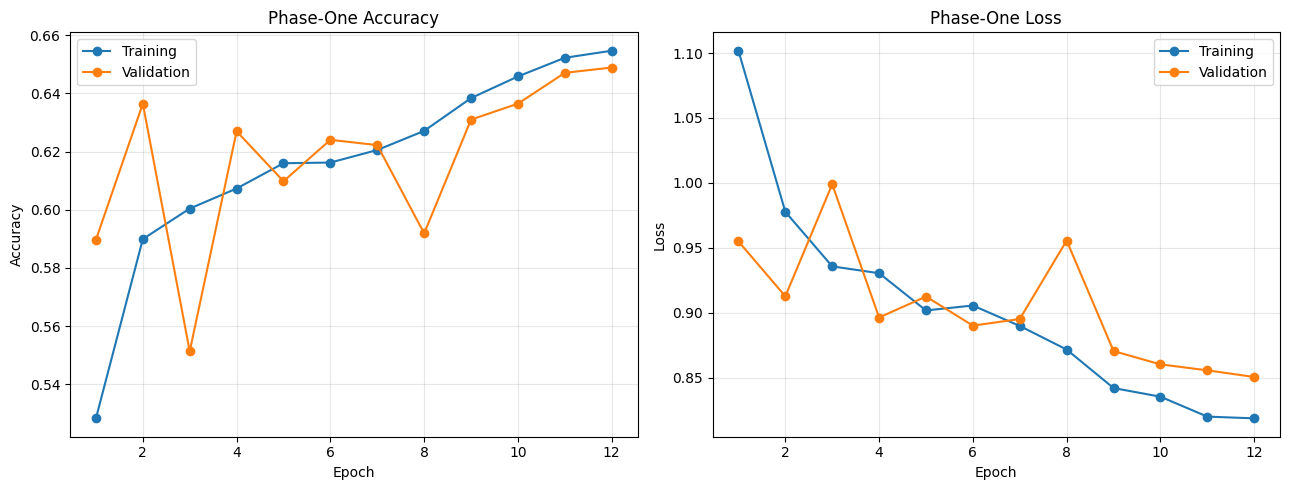

In [29]:
phase_one_results = pd.DataFrame(
    phase_one_history.history
)

phase_one_results.index += 1
phase_one_results.index.name = "epoch"

display(phase_one_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    phase_one_results.index,
    phase_one_results["accuracy"],
    marker="o",
    label="Training",
)
axes[0].plot(
    phase_one_results.index,
    phase_one_results["val_accuracy"],
    marker="o",
    label="Validation",
)
axes[0].set_title("Phase-One Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    phase_one_results.index,
    phase_one_results["loss"],
    marker="o",
    label="Training",
)
axes[1].plot(
    phase_one_results.index,
    phase_one_results["val_loss"],
    marker="o",
    label="Validation",
)
axes[1].set_title("Phase-One Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "phase_one_training_history.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Phase-one result

The frozen feature extractor produced a best validation accuracy of 64.89% and
a top-two accuracy of 89.08%. Training and validation accuracy remained close,
indicating that the model was not severely overfitting. Validation loss reached
its lowest value in the final epoch, suggesting that the model was still
learning. The final MobileNetV2 layers will now be fine-tuned with a much
smaller learning rate to adapt higher-level pretrained features to taro-leaf
disease patterns.

In [33]:
model = tf.keras.models.load_model(
    str(ARTIFACT_DIR / "phase_one_best.keras")
)

base_model = model.get_layer(
    "mobilenetv2_1.00_224"
)

# Fine-tune only the final 30 MobileNetV2 layers.
base_model.trainable = True
FINE_TUNE_LAYERS = 30

for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False

for layer in base_model.layers[-FINE_TUNE_LAYERS:]:
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization,
    ):
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5,
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy",
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=2,
            name="top_2_accuracy",
        ),
    ],
)

print("Reloaded the best phase-one model.")
print(
    "Trainable MobileNetV2 layers:",
    sum(layer.trainable for layer in base_model.layers),
)

Reloaded the best phase-one model.
Trainable MobileNetV2 layers: 19


In [34]:
final_model_path = (
    ARTIFACT_DIR / "taro_leaf_blight_model.keras"
)

fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(final_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        str(ARTIFACT_DIR / "fine_tuning_history.csv"),
        append=False,
    ),
]

### Phase 2: fine-tuning

The final 30 MobileNetV2 layers are unfrozen while earlier layers remain frozen.
A learning rate of 0.00001 is used to make small adjustments without destroying
the useful pretrained representations. The same class weights continue to
address the dataset imbalance.

In [35]:
import math

FINE_TUNE_EPOCHS = 8

training_steps = math.ceil(
    len(train_indices) / BATCH_SIZE
)

validation_steps = math.ceil(
    len(validation_indices) / BATCH_SIZE
)

fine_tune_history = model.fit(
    train_tf_dataset.repeat(),
    validation_data=validation_tf_dataset.repeat(),
    epochs=FINE_TUNE_EPOCHS,
    steps_per_epoch=training_steps,
    validation_steps=validation_steps,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks,
    verbose=1,
)

Epoch 1/8
399/400 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - accuracy: 0.6562 - loss: 0.8281 - top_2_accuracy: 0.8933
Epoch 1: val_loss improved from None to 0.87979, saving model to /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/taro_leaf_blight_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/taro_leaf_blight_model.keras
400/400 ━━━━━━━━━━━━━━━━━━━━ 230s 543ms/step - accuracy: 0.6547 - loss: 0.8194 - top_2_accuracy: 0.8970 - val_accuracy: 0.6281 - val_loss: 0.8798 - val_top_2_accuracy: 0.8915 - learning_rate: 1.0000e-05
Epoch 2/8
399/400 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - accuracy: 0.6671 - loss: 0.7889 - top_2_accuracy: 0.9046
Epoch 2: val_loss improved from 0.87979 to 0.82709, saving model to /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/taro_leaf_blight_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/taro_leaf_blight_model.keras
400/400 ━━━━━━━━━━━━━━━━━━━━ 2

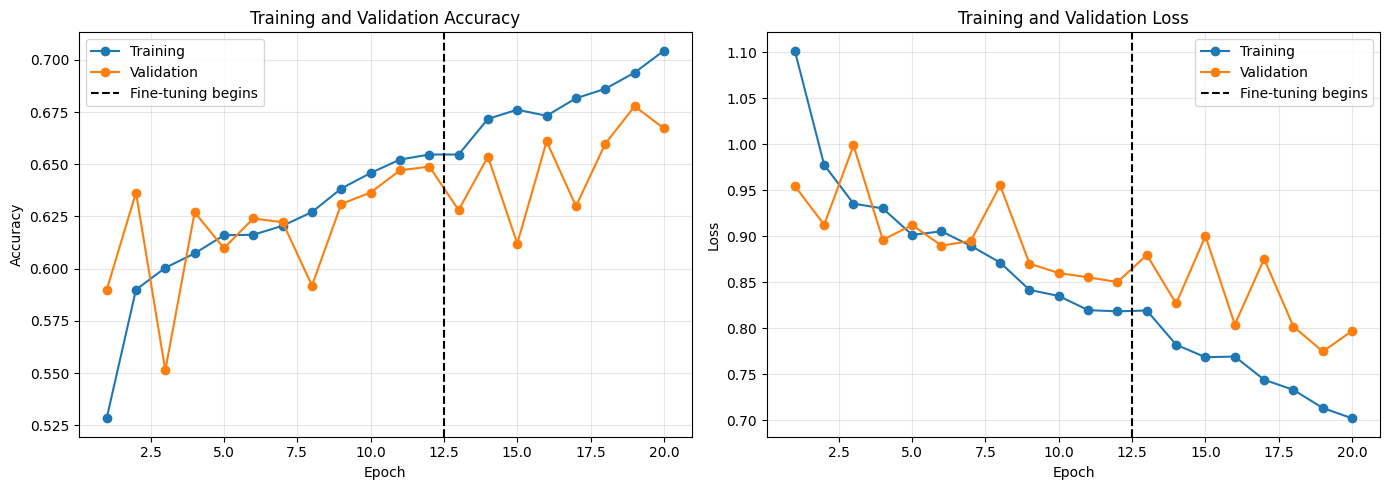

In [36]:
phase_one_epoch_count = len(
    phase_one_history.history["loss"]
)

combined_history = {}

for metric_name in [
    "accuracy",
    "val_accuracy",
    "loss",
    "val_loss",
]:
    combined_history[metric_name] = (
        phase_one_history.history[metric_name]
        + fine_tune_history.history[metric_name]
    )

epochs = np.arange(
    1,
    len(combined_history["loss"]) + 1,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    epochs,
    combined_history["accuracy"],
    marker="o",
    label="Training",
)
axes[0].plot(
    epochs,
    combined_history["val_accuracy"],
    marker="o",
    label="Validation",
)
axes[0].axvline(
    phase_one_epoch_count + 0.5,
    color="black",
    linestyle="--",
    label="Fine-tuning begins",
)
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs,
    combined_history["loss"],
    marker="o",
    label="Training",
)
axes[1].plot(
    epochs,
    combined_history["val_loss"],
    marker="o",
    label="Validation",
)
axes[1].axvline(
    phase_one_epoch_count + 0.5,
    color="black",
    linestyle="--",
    label="Fine-tuning begins",
)
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "complete_training_history.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## Final model evaluation

The best fine-tuned model is evaluated once on the held-out test set. Evaluation includes cross-entropy loss, accuracy, precision, recall, F1 score, top-two accuracy and multiclass ROC-AUC. Macro averages give equal importance to every class and are particularly important because the dataset is imbalanced.

In [37]:
from sklearn.metrics import top_k_accuracy_score

model = tf.keras.models.load_model(
    str(ARTIFACT_DIR / "taro_leaf_blight_model.keras")
)

test_probabilities = model.predict(
    test_tf_dataset,
    verbose=1,
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1,
)

true_test_labels = test_labels

assert len(test_predictions) == len(true_test_labels)

print(
    f"Generated predictions for "
    f"{len(test_predictions):,} test images."
)

86/86 ━━━━━━━━━━━━━━━━━━━━ 51s 525ms/step
Generated predictions for 2,738 test images.


In [38]:
test_accuracy = accuracy_score(
    true_test_labels,
    test_predictions,
)

test_loss = log_loss(
    true_test_labels,
    test_probabilities,
    labels=np.arange(len(class_names)),
)

macro_precision = precision_score(
    true_test_labels,
    test_predictions,
    average="macro",
    zero_division=0,
)

macro_recall = recall_score(
    true_test_labels,
    test_predictions,
    average="macro",
    zero_division=0,
)

macro_f1 = f1_score(
    true_test_labels,
    test_predictions,
    average="macro",
    zero_division=0,
)

weighted_f1 = f1_score(
    true_test_labels,
    test_predictions,
    average="weighted",
    zero_division=0,
)

test_top_2_accuracy = top_k_accuracy_score(
    true_test_labels,
    test_probabilities,
    k=2,
    labels=np.arange(len(class_names)),
)

binarized_test_labels = label_binarize(
    true_test_labels,
    classes=np.arange(len(class_names)),
)

macro_roc_auc = roc_auc_score(
    binarized_test_labels,
    test_probabilities,
    average="macro",
    multi_class="ovr",
)

evaluation_metrics = {
    "test_cross_entropy_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "top_2_accuracy": float(test_top_2_accuracy),
    "macro_roc_auc_ovr": float(macro_roc_auc),
}

metrics_table = pd.DataFrame(
    {
        "metric": evaluation_metrics.keys(),
        "value": evaluation_metrics.values(),
    }
)

display(
    metrics_table.style.format(
        {"value": "{:.4f}"}
    )
)

,metric,value
0,test_cross_entropy_loss,0.7407
1,test_accuracy,0.6972
2,macro_precision,0.6621
3,macro_recall,0.6574
4,macro_f1,0.6472
5,weighted_f1,0.7000
6,top_2_accuracy,0.9259
7,macro_roc_auc_ovr,0.8893


In [39]:
report = classification_report(
    true_test_labels,
    test_predictions,
    target_names=[
        name.replace("_", " ")
        for name in class_names
    ],
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).transpose()

display(
    report_df.style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1-score": "{:.4f}",
            "support": "{:.0f}",
        }
    )
)


,precision,recall,f1-score,support
Early Blight,0.5291,0.6849,0.5970,730
Healthy,0.8484,0.7934,0.8200,1312
Late Blight,0.5287,0.6789,0.5945,190
Mid Blight,0.7422,0.4723,0.5773,506
accuracy,0.6972,0.6972,0.6972,1
macro avg,0.6621,0.6574,0.6472,2738
weighted avg,0.7215,0.6972,0.7000,2738


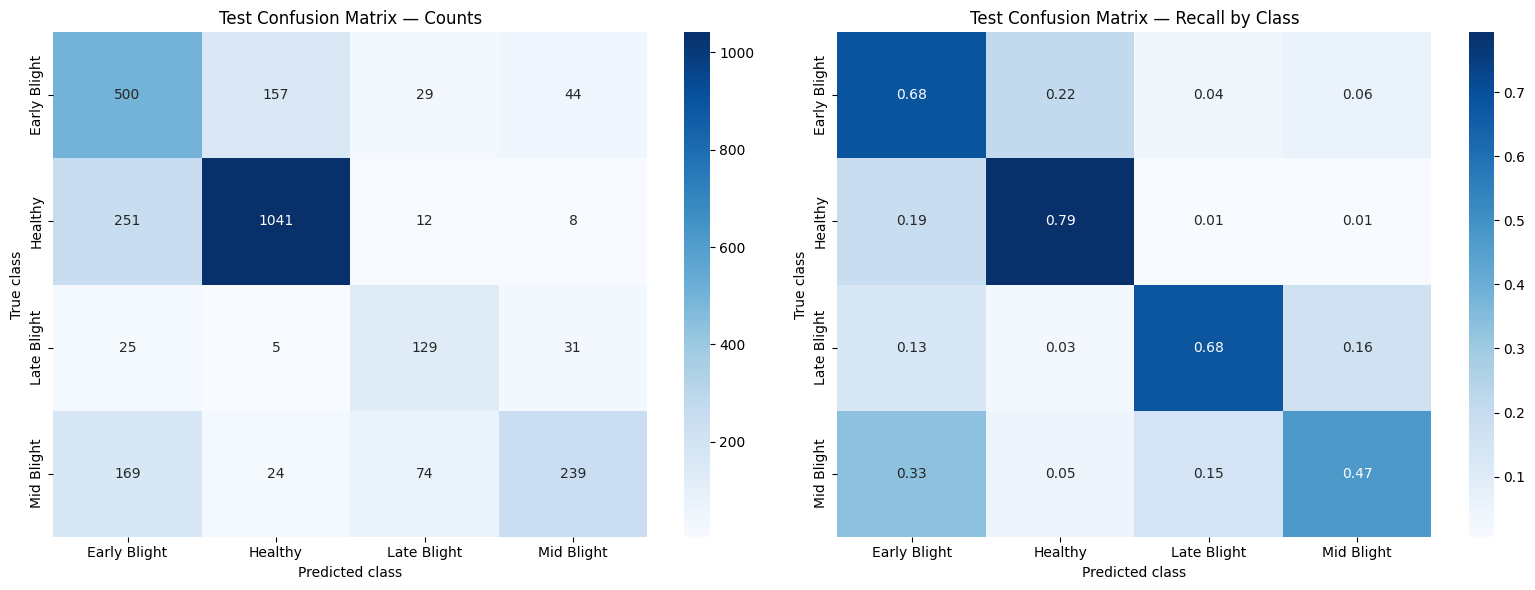

In [40]:
confusion = confusion_matrix(
    true_test_labels,
    test_predictions,
)

normalized_confusion = confusion_matrix(
    true_test_labels,
    test_predictions,
    normalize="true",
)

display_names = [
    name.replace("_", " ")
    for name in class_names
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=display_names,
    yticklabels=display_names,
    ax=axes[0],
)
axes[0].set_title("Test Confusion Matrix — Counts")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("True class")

sns.heatmap(
    normalized_confusion,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=display_names,
    yticklabels=display_names,
    ax=axes[1],
)
axes[1].set_title("Test Confusion Matrix — Recall by Class")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "test_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Evaluation interpretation

The model achieved 69.72% test accuracy, 64.72% macro F1 score, 92.59% top-two accuracy and 88.93% macro one-vs-rest ROC-AUC. The similar validation and test results suggest that performance generalized to the held-out test set.

Healthy leaves produced the strongest results, with 84.84% precision, 79.34% recall and an F1 score of 82.00%. Late Blight achieved 67.89% recall despite being the smallest class, indicating that class weighting helped the model learn minority-class examples. Its lower precision of 52.87% shows that some Early and Mid Blight images were incorrectly classified as Late Blight.

Mid Blight was the most difficult class, with 47.23% recall. Of 506 Mid Blight images, 169 were classified as Early Blight and 74 as Late Blight. This indicates that Mid Blight shares visual characteristics with the stages on either side of disease progression. Early Blight was also frequently confused with Healthy leaves.

The top-two accuracy of 92.59% is substantially higher than the top-one accuracy. This suggests that the correct disease stage is usually among the model's two most probable classes, but distinguishing adjacent disease stages remains difficult. The production interface should therefore display confidence scores and probability values rather than presenting predictions as certain diagnoses.

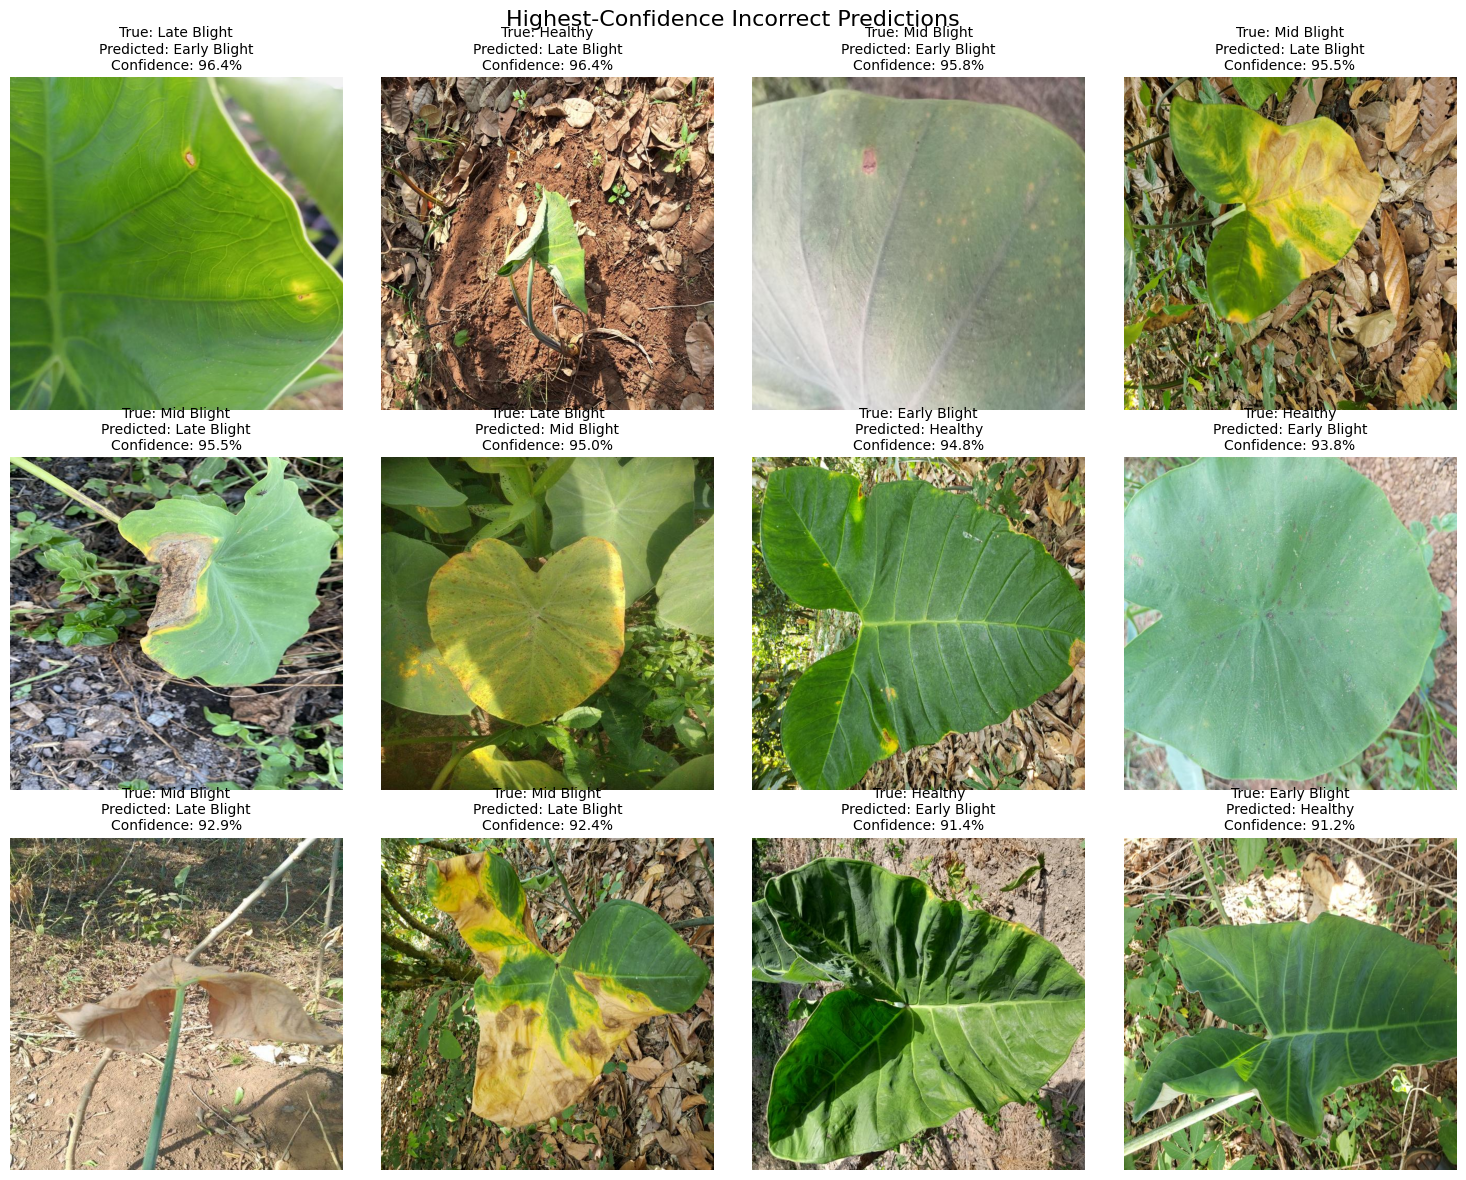

In [41]:
incorrect_positions = np.where(
    test_predictions != true_test_labels
)[0]

incorrect_confidences = test_probabilities[
    incorrect_positions
].max(axis=1)

sorted_error_positions = incorrect_positions[
    np.argsort(incorrect_confidences)[::-1]
]

number_of_errors_to_show = 12
selected_errors = sorted_error_positions[
    :number_of_errors_to_show
]

fig, axes = plt.subplots(3, 4, figsize=(15, 12))
axes = axes.flatten()

for axis, prediction_position in zip(
    axes,
    selected_errors,
):
    original_dataset_index = test_indices[
        prediction_position
    ]

    example = dataset[int(original_dataset_index)]
    image = example["image"].convert("RGB")

    true_index = int(true_test_labels[prediction_position])
    predicted_index = int(
        test_predictions[prediction_position]
    )
    confidence = float(
        test_probabilities[
            prediction_position,
            predicted_index,
        ]
    )

    axis.imshow(image)
    axis.set_title(
        f"True: {class_names[true_index].replace('_', ' ')}\n"
        f"Predicted: "
        f"{class_names[predicted_index].replace('_', ' ')}\n"
        f"Confidence: {confidence:.1%}",
        fontsize=10,
    )
    axis.axis("off")

plt.suptitle(
    "Highest-Confidence Incorrect Predictions",
    fontsize=16,
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "misclassified_examples.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Error-analysis conclusion

The confusion matrix and misclassified examples show that most errors occur between visually adjacent disease stages rather than between completely unrelated classes. Lighting, leaf age, background vegetation, camera distance and the proportion of the affected leaf visible in each image may also influence predictions. Future improvements could include additional expert-labelled Mid Blight images, lesion segmentation, higher-resolution inputs, probability calibration and evaluation using farm-based groups to prevent similar images from the same location appearing across different splits.

In [43]:
# Reload the best fine-tuned model.
model = tf.keras.models.load_model(
    str(ARTIFACT_DIR / "taro_leaf_blight_model.keras")
)

base_model = model.get_layer(
    "mobilenetv2_1.00_224"
)

# Build an inference-only model without augmentation.
inference_inputs = tf.keras.Input(
    shape=(*IMAGE_SIZE, 3),
    name="input_image",
)

x = tf.keras.applications.mobilenet_v2.preprocess_input(
    inference_inputs
)

x = base_model(
    x,
    training=False,
)

x = model.get_layer(
    "global_average_pooling"
)(x)

x = model.get_layer(
    "classification_features"
)(x)

# Dropout is automatically disabled during prediction.
x = model.get_layer("dropout")(
    x,
    training=False,
)

inference_outputs = model.get_layer(
    "predictions"
)(x)

inference_model = tf.keras.Model(
    inputs=inference_inputs,
    outputs=inference_outputs,
    name="taro_leaf_blight_inference_model",
)

h5_model_path = (
    ARTIFACT_DIR / "taro_leaf_blight_model.h5"
)
class_names_path = ARTIFACT_DIR / "class_names.json"
metrics_path = ARTIFACT_DIR / "metrics.json"
report_path = ARTIFACT_DIR / "classification_report.csv"
metadata_path = ARTIFACT_DIR / "model_metadata.json"

# Confirm that removing augmentation does not change inference output.
original_probabilities = model.predict(
    batch_images[:1],
    verbose=0,
)

inference_probabilities = inference_model.predict(
    batch_images[:1],
    verbose=0,
)

np.testing.assert_allclose(
    original_probabilities,
    inference_probabilities,
    rtol=1e-5,
    atol=1e-5,
)

# Save the inference-only model in the rubric's accepted H5 format.
inference_model.save(
    str(h5_model_path),
    include_optimizer=False,
)

with open(
    class_names_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(class_names, file, indent=2)

with open(
    metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(evaluation_metrics, file, indent=2)

report_df.to_csv(report_path)

model_metadata = {
    "model_name": "Taro Leaf Blight MobileNetV2",
    "model_version": "1.0.0",
    "dataset": (
        "Project-AgML/"
        "taro_blight_stage_classification"
    ),
    "input_height": IMAGE_SIZE[0],
    "input_width": IMAGE_SIZE[1],
    "input_channels": 3,
    "class_names": class_names,
    "preprocessing": (
        "Convert to RGB and resize with padding to "
        "224x224. MobileNetV2 preprocessing is built "
        "into the exported model."
    ),
    "test_images": int(len(test_labels)),
    "metrics": evaluation_metrics,
}

with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(model_metadata, file, indent=2)

print("Inference outputs match the original model.")
print("Saved artifacts:")
print(f"- Keras training model: {final_model_path}")
print(f"- H5 inference model: {h5_model_path}")
print(f"- Class names: {class_names_path}")
print(f"- Metrics: {metrics_path}")
print(f"- Classification report: {report_path}")
print(f"- Model metadata: {metadata_path}")

Inference outputs match the original model.
Saved artifacts:
- Keras training model: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/taro_leaf_blight_model.keras
- H5 inference model: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/taro_leaf_blight_model.h5
- Class names: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/class_names.json
- Metrics: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/metrics.json
- Classification report: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/classification_report.csv
- Model metadata: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/artifacts/model_metadata.json


In [45]:
# Build an H5-compatible inference model.
h5_inputs = tf.keras.Input(
    shape=(*IMAGE_SIZE, 3),
    name="input_image",
)

# Equivalent to MobileNetV2 preprocess_input:
# pixel / 127.5 - 1.0
x = tf.keras.layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="mobilenet_rescaling",
)(h5_inputs)

x = base_model(
    x,
    training=False,
)

x = model.get_layer(
    "global_average_pooling"
)(x)

x = model.get_layer(
    "classification_features"
)(x)

x = model.get_layer("dropout")(
    x,
    training=False,
)

h5_outputs = model.get_layer(
    "predictions"
)(x)

h5_compatible_model = tf.keras.Model(
    inputs=h5_inputs,
    outputs=h5_outputs,
    name="taro_leaf_blight_h5_inference",
)

# Confirm equivalent predictions before overwriting the file.
h5_compatible_probabilities = (
    h5_compatible_model.predict(
        batch_images[:1],
        verbose=0,
    )
)

np.testing.assert_allclose(
    original_probabilities,
    h5_compatible_probabilities,
    rtol=1e-5,
    atol=1e-5,
)

# Overwrite the incompatible H5 export.
h5_compatible_model.save(
    str(h5_model_path),
    include_optimizer=False,
)

print("H5-compatible model saved successfully.")

H5-compatible model saved successfully.


In [46]:
exported_model = tf.keras.models.load_model(
    str(h5_model_path),
    compile=False,
)

verification_probabilities = exported_model.predict(
    batch_images[:1],
    verbose=0,
)

np.testing.assert_allclose(
    h5_compatible_probabilities,
    verification_probabilities,
    rtol=1e-5,
    atol=1e-5,
)

predicted_index = int(
    np.argmax(verification_probabilities[0])
)

print("H5 model loaded and verified successfully.")
print(
    "Sample prediction:",
    class_names[predicted_index],
)
print(
    "Confidence:",
    f"{verification_probabilities[0, predicted_index]:.2%}",
)

H5 model loaded and verified successfully.
Sample prediction: Mid_Blight
Confidence: 84.30%


In [47]:
import zipfile

package_path = (
    PROJECT_DIR / "taro_model_artifacts.zip"
)

artifact_files = [
    ARTIFACT_DIR / "taro_leaf_blight_model.keras",
    ARTIFACT_DIR / "taro_leaf_blight_model.h5",
    ARTIFACT_DIR / "class_names.json",
    ARTIFACT_DIR / "metrics.json",
    ARTIFACT_DIR / "classification_report.csv",
    ARTIFACT_DIR / "model_metadata.json",
    ARTIFACT_DIR / "data_split_indices.npz",
    ARTIFACT_DIR / "phase_one_history.csv",
    ARTIFACT_DIR / "fine_tuning_history.csv",
]

figure_files = list(FIGURE_DIR.glob("*.png"))

with zipfile.ZipFile(
    package_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for file_path in artifact_files:
        if file_path.exists():
            archive.write(
                file_path,
                arcname=f"models/{file_path.name}",
            )

    for file_path in figure_files:
        archive.write(
            file_path,
            arcname=f"figures/{file_path.name}",
        )

print(f"Created package: {package_path}")
print(f"Included model artifacts: {len(artifact_files)}")
print(f"Included figures: {len(figure_files)}")

Created package: /content/drive/MyDrive/MLOps_Taro_Leaf_Blight/taro_model_artifacts.zip
Included model artifacts: 9
Included figures: 6
